# Superconductor Critical Temperature Prediction — SVR + BO/GA/PSO\n\nThis notebook adapts the supplied GPR optimization workflow to **Support Vector Regression (SVR)**. It compares Bayesian Optimization (BO), Genetic Algorithm (GA), and Particle Swarm Optimization (PSO) for tuning `C`, `epsilon`, and `gamma`.\n\n**How to run:** Set `DATA_PATH` near the top of the code cell to the exact path of your `train.csv` file. For files stored in Google Drive, mount Drive and use the path under `/content/drive/MyDrive/`. The CSV must contain a `critical_temp` target column.\n\nThe code uses fixed tuning subsets for a manageable runtime. Final results depend on the dataset and runtime; no metric values are assumed in advance.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 11.6 MB/s eta 0:00:00
SVR HYPERPARAMETER OPTIMIZATION
Loaded file: /content/train (2).csv
Dataset shape: (21263, 84)
Columns: ['formula', 'rawMaterial', 'number_of_elements', 'mean_atomic_mass', 'wtd_mean_atomic_mass', 'gmean_atomic_mass', 'wtd_gmean_atomic_mass', 'entropy_atomic_mass', 'wtd_entropy_atomic_mass', 'range_atomic_mass', 'wtd_range_atomic_mass', 'std_atomic_mass', 'wtd_std_atomic_mass', 'mean_fie', 'wtd_mean_fie', 'gmean_fie', 'wtd_gmean_fie', 'entropy_fie', 'wtd_entropy_fie', 'range_fie', 'wtd_range_fie', 'std_fie', 'wtd_std_fie', 'mean_atomic_radius', 'wtd_mean_atomic_radius', 'gmean_atomic_radius', 'wtd_gmean_atomic_radius', 'entropy_atomic_radius', 'wtd_entropy_atomic_radius', 'range_atomic_radius', 'wtd_range_atomic_radius', 'std_atomic_radius', 'wtd_std_atomic_radius', 'mean_Density', 'wtd_mean_Density', 'gmean_Density', 'wtd_gmean_Density', 'entropy_Density', 'wtd_entropy_Density', 'range_Density', 'wtd_rang

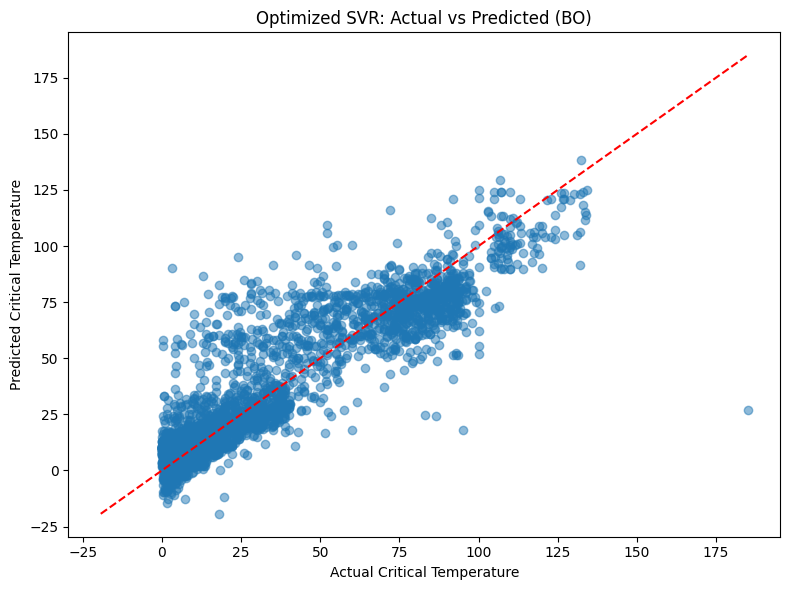

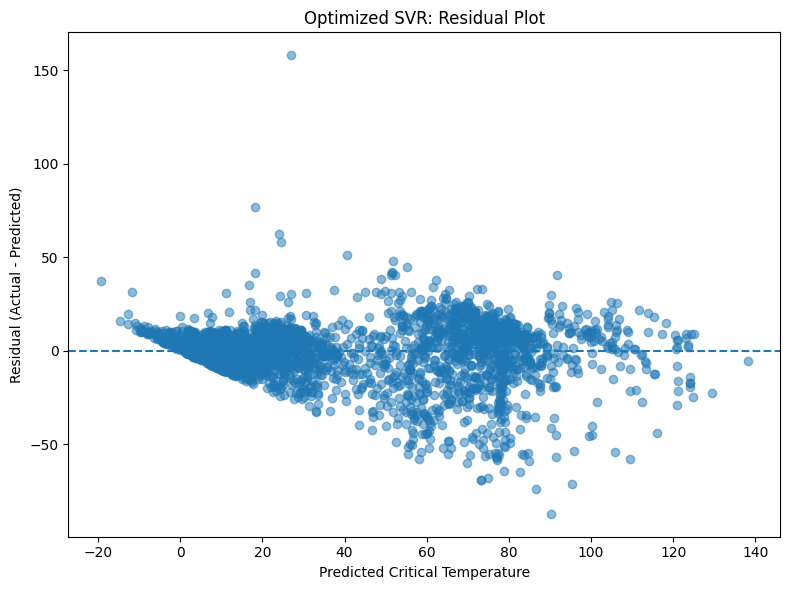


SVR optimization experiment completed.
To download results, run the optional cell below.


In [1]:
# ==========================================================
# SUPERCONDUCTOR CRITICAL TEMPERATURE PREDICTION
# SVR HYPERPARAMETER OPTIMIZATION USING BO, GA AND PSO
# Google Colab-ready version
# ==========================================================

# If needed, install the Bayesian Optimization package.
%pip -q install scikit-optimize

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from skopt import gp_minimize
from skopt.space import Real

warnings.filterwarnings("ignore")

# ==========================================================
# 1. CONFIGURATION
# ==========================================================

TARGET = "critical_temp"
SEED = 42

# Small, fixed subsets make optimization faster.
TUNE_TRAIN_SIZE = 600
TUNE_VAL_SIZE = 2000

# Equal evaluation budget: 24 objective evaluations per optimizer.
BO_CALLS = 24
GA_POPULATION = 6
GA_GENERATIONS = 3       # initial population + 3 generations = 24 evaluations
PSO_PARTICLES = 6
PSO_ITERATIONS = 3       # initial swarm + 3 iterations = 24 evaluations

# SVR with an RBF kernel is usually manageable on this final subset.
FINAL_TRAIN_SIZE = 5000

# ==========================================================
# 2. UPLOAD DATA AND SPLIT
# ==========================================================

# ==========================================================
# IMPORTANT: EDIT THIS PATH TO THE LOCATION OF YOUR CSV FILE
# ==========================================================
# Example for a file uploaded to the Colab session:
# DATA_PATH = "/content/train.csv"
#
# Example for a file in Google Drive:
# DATA_PATH = "/content/drive/MyDrive/material_modelling_project/train.csv"

DATA_PATH = "/content/train (2).csv"  # <-- CHANGE THIS PATH

# If the file is in Google Drive, uncomment and run these two lines,
# then set DATA_PATH to the correct path inside MyDrive:
# from google.colab import drive
# drive.mount("/content/drive")

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Could not find the dataset at: {DATA_PATH}\\n"
        "Edit DATA_PATH above to the exact location of your CSV file."
    )

df = pd.read_csv(DATA_PATH)

print("=" * 65)
print("SVR HYPERPARAMETER OPTIMIZATION")
print("=" * 65)
print("Loaded file:", DATA_PATH)
print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found. "
        f"Available columns: {list(df.columns)}"
    )

# Keep numeric predictors only; target must be numeric.
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).copy()

X = df.drop(columns=[TARGET])
X = X.select_dtypes(include=[np.number])
y = df[TARGET].astype(float)

if X.shape[1] == 0:
    raise ValueError("No numeric feature columns were found.")

# Remove columns that are entirely missing.
X = X.dropna(axis=1, how="all")

if X.shape[1] == 0:
    raise ValueError("All feature columns are missing or non-numeric.")

print("Numeric feature count:", X.shape[1])
print("Rows after removing missing target values:", len(df))
print("Missing feature values:", int(X.isna().sum().sum()))

# Same 70/15/15 split as the friend's code.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

# Fit imputation and scaling on training data only.
# This prevents validation/test information from leaking into preprocessing.
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

# ==========================================================
# 3. FIXED TUNING SUBSETS
# ==========================================================

rng = np.random.default_rng(SEED)

train_size = min(TUNE_TRAIN_SIZE, len(X_train_scaled))
train_indices = rng.choice(len(X_train_scaled), train_size, replace=False)
X_tune = X_train_scaled[train_indices]
y_tune = y_train.iloc[train_indices].to_numpy()

val_size = min(TUNE_VAL_SIZE, len(X_val_scaled))
val_indices = rng.choice(len(X_val_scaled), val_size, replace=False)
X_val_tune = X_val_scaled[val_indices]
y_val_tune = y_val.iloc[val_indices].to_numpy()

print("\nOptimization training subset:", X_tune.shape)
print("Optimization validation subset:", X_val_tune.shape)

# ==========================================================
# 4. SVR HYPERPARAMETER SEARCH SPACE
# ==========================================================
# Optimize log10(C), log10(epsilon), and log10(gamma).
# C controls regularization; epsilon controls the insensitive tube;
# gamma controls the influence range of each sample for the RBF kernel.

LOWER = np.array([-1.0, -3.0, -4.0])
UPPER = np.array([ 3.0,  1.0,  1.0])

evaluation_count = 0

def decode_params(params):
    """Convert log10 coordinates to actual SVR hyperparameters."""
    return {
        "C": float(10 ** params[0]),
        "epsilon": float(10 ** params[1]),
        "gamma": float(10 ** params[2]),
    }

def objective(params):
    """Minimize RMSE on one fixed tuning-validation subset."""
    global evaluation_count
    evaluation_count += 1

    p = decode_params(params)

    try:
        model = SVR(
            kernel="rbf",
            C=p["C"],
            epsilon=p["epsilon"],
            gamma=p["gamma"],
            cache_size=1000
        )
        model.fit(X_tune, y_tune)
        pred = model.predict(X_val_tune)
        rmse = np.sqrt(mean_squared_error(y_val_tune, pred))

        if not np.isfinite(rmse):
            return 1e10
        return float(rmse)

    except (ValueError, np.linalg.LinAlgError, FloatingPointError):
        return 1e10

# ==========================================================
# 5. BAYESIAN OPTIMIZATION (BO)
# ==========================================================

print("\n" + "=" * 65)
print("BAYESIAN OPTIMIZATION (BO)")
print("=" * 65)

start = time.time()
bo_result = gp_minimize(
    func=objective,
    dimensions=[
        Real(-1.0, 3.0, name="log10_C"),
        Real(-3.0, 1.0, name="log10_epsilon"),
        Real(-4.0, 1.0, name="log10_gamma"),
    ],
    n_calls=BO_CALLS,
    n_initial_points=8,
    random_state=SEED
)
bo_time = time.time() - start
bo_params = np.array(bo_result.x)
bo_rmse = float(bo_result.fun)

print("Best BO tuning RMSE:", round(bo_rmse, 4))
print("Best BO parameters:", decode_params(bo_params))
print("BO runtime:", round(bo_time, 2), "seconds")

# ==========================================================
# 6. GENETIC ALGORITHM (GA)
# ==========================================================

def genetic_algorithm():
    local_rng = np.random.default_rng(SEED)
    population = local_rng.uniform(
        LOWER, UPPER, size=(GA_POPULATION, len(LOWER))
    )
    scores = np.array([objective(ind) for ind in population])

    best_idx = np.argmin(scores)
    best_params = population[best_idx].copy()
    best_score = float(scores[best_idx])

    for generation in range(GA_GENERATIONS):
        new_population = [best_params.copy()]  # elitism

        while len(new_population) < GA_POPULATION:
            # Tournament selection: parent 1
            candidates = local_rng.choice(GA_POPULATION, size=3, replace=False)
            parent1 = population[candidates[np.argmin(scores[candidates])]]

            # Tournament selection: parent 2
            candidates = local_rng.choice(GA_POPULATION, size=3, replace=False)
            parent2 = population[candidates[np.argmin(scores[candidates])]]

            # Blend crossover
            weight = local_rng.random()
            child = weight * parent1 + (1 - weight) * parent2

            # Mutation
            mask = local_rng.random(len(LOWER)) < 0.30
            if mask.any():
                child[mask] += local_rng.normal(0, 0.15, size=mask.sum())

            child = np.clip(child, LOWER, UPPER)
            new_population.append(child)

        population = np.array(new_population)
        scores = np.array([objective(ind) for ind in population])

        generation_best = np.argmin(scores)
        if scores[generation_best] < best_score:
            best_score = float(scores[generation_best])
            best_params = population[generation_best].copy()

        print(f"GA Generation {generation + 1}: Best RMSE = {best_score:.4f}")

    return best_params, best_score

print("\n" + "=" * 65)
print("GENETIC ALGORITHM (GA)")
print("=" * 65)

start = time.time()
ga_params, ga_rmse = genetic_algorithm()
ga_time = time.time() - start

print("Best GA tuning RMSE:", round(ga_rmse, 4))
print("Best GA parameters:", decode_params(ga_params))
print("GA runtime:", round(ga_time, 2), "seconds")

# ==========================================================
# 7. PARTICLE SWARM OPTIMIZATION (PSO)
# ==========================================================

def particle_swarm():
    local_rng = np.random.default_rng(SEED)
    positions = local_rng.uniform(
        LOWER, UPPER, size=(PSO_PARTICLES, len(LOWER))
    )
    velocities = np.zeros_like(positions)

    personal_best = positions.copy()
    personal_scores = np.array([objective(pos) for pos in positions])

    idx = np.argmin(personal_scores)
    global_best = personal_best[idx].copy()
    global_score = float(personal_scores[idx])

    inertia = 0.7
    cognitive = 1.5
    social = 1.5

    for iteration in range(PSO_ITERATIONS):
        for i in range(PSO_PARTICLES):
            r1 = local_rng.random(len(LOWER))
            r2 = local_rng.random(len(LOWER))

            velocities[i] = (
                inertia * velocities[i]
                + cognitive * r1 * (personal_best[i] - positions[i])
                + social * r2 * (global_best - positions[i])
            )

            positions[i] = np.clip(
                positions[i] + velocities[i], LOWER, UPPER
            )

            score = objective(positions[i])

            if score < personal_scores[i]:
                personal_scores[i] = score
                personal_best[i] = positions[i].copy()

            if score < global_score:
                global_score = float(score)
                global_best = positions[i].copy()

        print(f"PSO Iteration {iteration + 1}: Best RMSE = {global_score:.4f}")

    return global_best, global_score

print("\n" + "=" * 65)
print("PARTICLE SWARM OPTIMIZATION (PSO)")
print("=" * 65)

start = time.time()
pso_params, pso_rmse = particle_swarm()
pso_time = time.time() - start

print("Best PSO tuning RMSE:", round(pso_rmse, 4))
print("Best PSO parameters:", decode_params(pso_params))
print("PSO runtime:", round(pso_time, 2), "seconds")

# ==========================================================
# 8. COMPARE ALL THREE OPTIMIZERS
# ==========================================================

comparison = pd.DataFrame([
    {
        "Model": "SVR-RBF",
        "Method": "BO",
        "Tuning_Validation_RMSE": bo_rmse,
        "Runtime_seconds": bo_time,
        **decode_params(bo_params)
    },
    {
        "Model": "SVR-RBF",
        "Method": "GA",
        "Tuning_Validation_RMSE": ga_rmse,
        "Runtime_seconds": ga_time,
        **decode_params(ga_params)
    },
    {
        "Model": "SVR-RBF",
        "Method": "PSO",
        "Tuning_Validation_RMSE": pso_rmse,
        "Runtime_seconds": pso_time,
        **decode_params(pso_params)
    }
])

comparison.to_csv("SVR_Optimization_Comparison.csv", index=False)
print("\nOPTIMIZER COMPARISON")
print(comparison.to_string(index=False))

# Choose the optimizer using tuning-validation RMSE only.
results = [
    ("BO", bo_rmse, bo_params),
    ("GA", ga_rmse, ga_params),
    ("PSO", pso_rmse, pso_params)
]
best_method, best_tuning_rmse, best_params = min(
    results, key=lambda item: item[1]
)
best_values = decode_params(best_params)

print("\nSelected optimizer:", best_method)
print("Selected SVR parameters:", best_values)

# ==========================================================
# 9. FIT FINAL SELECTED SVR
# ==========================================================

# Use a deterministic training subset for runtime control.
final_size = min(FINAL_TRAIN_SIZE, len(X_train_scaled))
final_rng = np.random.default_rng(SEED)
final_indices = final_rng.choice(
    len(X_train_scaled), final_size, replace=False
)

X_train_final = X_train_scaled[final_indices]
y_train_final = y_train.iloc[final_indices].to_numpy()

svr_optimized = SVR(
    kernel="rbf",
    C=best_values["C"],
    epsilon=best_values["epsilon"],
    gamma=best_values["gamma"],
    cache_size=1000
)

print("\nFitting final optimized SVR...")
print("Final training samples:", final_size)
svr_optimized.fit(X_train_final, y_train_final)

# ==========================================================
# 10. VALIDATION EVALUATION
# ==========================================================

y_val_pred = svr_optimized.predict(X_val_scaled)

val_mae = mean_absolute_error(y_val, y_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
val_r2 = r2_score(y_val, y_val_pred)

print("\nFULL VALIDATION RESULTS")
print("MAE :", round(val_mae, 4))
print("RMSE:", round(val_rmse, 4))
print("R²  :", round(val_r2, 4))

# ==========================================================
# 11. FINAL TEST EVALUATION
# ==========================================================

y_test_pred = svr_optimized.predict(X_test_scaled)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("\nFINAL TEST RESULTS")
print("Selected optimizer:", best_method)
print("MAE :", round(test_mae, 4))
print("RMSE:", round(test_rmse, 4))
print("R²  :", round(test_r2, 4))

# ==========================================================
# 12. SAVE FINAL RESULTS
# ==========================================================

final_metrics = pd.DataFrame([{
    "Model": "SVR-RBF",
    "Selected_Optimizer": best_method,
    "Tuning_Validation_RMSE": best_tuning_rmse,
    "C": best_values["C"],
    "epsilon": best_values["epsilon"],
    "gamma": best_values["gamma"],
    "Validation_MAE": val_mae,
    "Validation_RMSE": val_rmse,
    "Validation_R2": val_r2,
    "Test_MAE": test_mae,
    "Test_RMSE": test_rmse,
    "Test_R2": test_r2,
    "Final_Training_Samples": final_size
}])
final_metrics.to_csv("SVR_Optimized_Final_Metrics.csv", index=False)

predictions = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_test_pred
})
predictions.to_csv("SVR_Optimized_Predictions.csv", index=False)

print("\nSaved result files:")
print("- SVR_Optimization_Comparison.csv")
print("- SVR_Optimized_Final_Metrics.csv")
print("- SVR_Optimized_Predictions.csv")

# ==========================================================
# 13. ACTUAL VS PREDICTED PLOT
# ==========================================================

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.5)

low = min(float(y_test.min()), float(np.min(y_test_pred)))
high = max(float(y_test.max()), float(np.max(y_test_pred)))
plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual Critical Temperature")
plt.ylabel("Predicted Critical Temperature")
plt.title(f"Optimized SVR: Actual vs Predicted ({best_method})")
plt.tight_layout()
plt.savefig("SVR_Optimized_Actual_vs_Predicted.png", dpi=300)
plt.show()

# ==========================================================
# 14. RESIDUAL PLOT
# ==========================================================

residuals = y_test.to_numpy() - y_test_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_test_pred, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Critical Temperature")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Optimized SVR: Residual Plot")
plt.tight_layout()
plt.savefig("SVR_Optimized_Residuals.png", dpi=300)
plt.show()

# ==========================================================
# 15. DOWNLOAD RESULTS FROM COLAB
# ==========================================================

print("\nSVR optimization experiment completed.")
print("To download results, run the optional cell below.")


In [2]:
# Optional: download the CSV result files and plots to your computer.
from google.colab import files
for filename in [
    'SVR_Optimization_Comparison.csv',
    'SVR_Optimized_Final_Metrics.csv',
    'SVR_Optimized_Predictions.csv',
    'SVR_Optimized_Actual_vs_Predicted.png',
    'SVR_Optimized_Residuals.png',
]:
    files.download(filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>